# 1. Data, TF-IDF baseline and DistilBERT detector (RQ1 and RQ2)

In [1]:
# !pip install -q datasets transformers accelerate scikit-learn

In [2]:
import os, re, random
os.environ["HF_HUB_DISABLE_SYMLINKS_WARNING"] = "1" 
import numpy as np
import pandas as pd

SEED = 42
random.seed(SEED)
np.random.seed(SEED)

# All outputs (data splits, results tables, figures) go into a "results" folder
PROJECT_DIR = r"C:\Users\thiga\OneDrive\Documents\Masters - Big Data\Year 1\Semester 2\COS 802\Project"
OUT = os.path.join(PROJECT_DIR, "results")

if not os.path.isdir(PROJECT_DIR):
    raise FileNotFoundError(f"Project folder not found: {PROJECT_DIR}. Check the path.")

os.makedirs(OUT, exist_ok=True)
print("Saving to:", OUT)

Saving to: C:\Users\thiga\OneDrive\Documents\Masters - Big Data\Year 1\Semester 2\COS 802\Project\results


In [3]:
import matplotlib.pyplot as plt

COLORS = ["seagreen", "dodgerblue", "darkorange"]

def style(ax):

    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)
    ax.grid(False)
    ax.tick_params(axis="both", direction="in", length=4, width=0.8)


def save_panel(fig, ax, filename):

    fig.canvas.draw()

    renderer = fig.canvas.get_renderer()
    box = ax.get_tightbbox(renderer)
    box = box.transformed(fig.dpi_scale_trans.inverted())
    box = box.padded(0.08)

    fig.savefig(
        f"{OUT}/{filename}.png",
        dpi=300,
        bbox_inches=box)

## Data
* **QQP**: 10,000 pairs sampled from the GLUE copy of Quora Question Pairs, split 8,000 train / 1,000 validation / 1,000 test.
* **PAWS**: 8,000 pair test split. The Hugging Face copy does not include PAWS-QQP.

In [4]:
from datasets import load_dataset

qqp = load_dataset("nyu-mll/glue", "qqp")["train"].shuffle(seed=SEED).select(range(10_000)).to_pandas()
qqp = qqp.rename(columns={"question1": "sentence1", "question2": "sentence2"})[["sentence1", "sentence2", "label"]]
qqp_train = qqp.iloc[:8000].reset_index(drop=True)
qqp_val   = qqp.iloc[8000:9000].reset_index(drop=True)
qqp_test  = qqp.iloc[9000:].reset_index(drop=True)

paws_test = load_dataset("google-research-datasets/paws", "labeled_final")["test"].to_pandas()
paws_test = paws_test[["sentence1", "sentence2", "label"]]

splits = {"qqp_train": qqp_train, "qqp_val": qqp_val, "qqp_test": qqp_test, "paws_test": paws_test}
for name, df in splits.items():
    df.to_csv(f"{OUT}/{name}.csv", index=False)
    print(f"{name:10s} {len(df):5d} pairs, {df.label.mean():.1%} paraphrases")

qqp_train   8000 pairs, 36.8% paraphrases
qqp_val     1000 pairs, 35.8% paraphrases
qqp_test    1000 pairs, 34.9% paraphrases
paws_test   8000 pairs, 44.2% paraphrases


## Evaluation helper
Accuracy, precision, recall, F1, ROC-AUC and the confusion matrix counts (TN, FP, FN, TP).

In [5]:
from sklearn.metrics import accuracy_score, precision_recall_fscore_support, roc_auc_score, confusion_matrix

results = []   
probs = {}    

def log_results(model_name, dataset_name, y_true, prob): #Score one model on one dataset and store the result.

    y_true = np.asarray(y_true)
    prob = np.asarray(prob)

    probs[(model_name, dataset_name)] = (y_true, prob)

    pred = (prob >= 0.5).astype(int)

    precision, recall, f1, _ = precision_recall_fscore_support(y_true, pred, average="binary", zero_division=0)

    # Confusion matrix counts
    tn, fp, fn, tp = confusion_matrix(y_true, pred, labels=[0, 1]).ravel()

    results.append({"model": model_name,
        "dataset": dataset_name,
        "accuracy": accuracy_score(y_true, pred),
        "precision": precision,
        "recall": recall,
        "f1": f1,
        "roc_auc": roc_auc_score(y_true, prob),
        "TN": tn, "FP": fp, "FN": fn, "TP": tp,})

## Baseline: TF-IDF + Logistic Regression

### 1. How does it work?

First, **TF-IDF** converts each sentence into numbers based on the words it contains and how important those words are.

Sentences are compared using:

- **Cosine similarity:** Measures how similar the words in the two sentences are. A value closer to 1 means they use more similar words.
- **Absolute difference:** Measures how much the numerical values differ between the two sentences.

These values are given to **Logistic Regression**, which predicts whether the sentences have the same meaning (paraphrase = 1) or different meanings (not paraphrase = 0).

### 2. Regularisation (C)?

C is used to prevent overfitting (memorising the training data instead of learning patterns):

- **C = 0.1**: Strong penalty.
- **C = 1**: Moderate penalty.
- **C = 10**: Weak penalty.

**Lowest validation loss** value is chosen.

### 3. DistilBERT

Same selection method for both models:

- **Logistic Regression:** Choose the best **C** value based on validation loss.
- **DistilBERT:** Choose the best training epoch based on validation loss.

In [6]:
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import log_loss, f1_score
from scipy.sparse import hstack, csr_matrix

tfidf = TfidfVectorizer(lowercase=True, ngram_range=(1, 2), min_df=2)
training_sentences = pd.concat([qqp_train.sentence1, qqp_train.sentence2])
tfidf.fit(training_sentences)


# Convert sentence pairs into features for Logistic Regression
def pair_features(df):

    a = tfidf.transform(df.sentence1)
    b = tfidf.transform(df.sentence2)

    difference = abs(a - b)

    cosine = csr_matrix(np.asarray(a.multiply(b).sum(axis=1)))
    features = hstack([difference, cosine]).tocsr()

    return features


X_train = pair_features(qqp_train)
X_val = pair_features(qqp_val)


# Test different regularisation strengths
best_loss = np.inf

for C in [0.1, 1, 10]:

    model = LogisticRegression(C=C, max_iter=1000, random_state=SEED)
    model.fit(X_train, qqp_train.label)

    val_prob = model.predict_proba(X_val)[:, 1]

    val_loss = log_loss(qqp_val.label, val_prob)
    val_f1 = f1_score(qqp_val.label, val_prob >= 0.5)

    print(f"C={C:<4}  validation loss {val_loss:.4f}  validation F1 {val_f1:.3f}")

    # Keep model with the lowest validation loss
    if val_loss < best_loss:
        best_loss = val_loss
        best_C = C
        lr = model

print("Selected C =", best_C)


# Datasets to evaluate
datasets = [("QQP val", qqp_val), ("QQP test", qqp_test), ("PAWS test", paws_test)]

for name, df in datasets:

    prob = lr.predict_proba(pair_features(df))[:, 1]

    log_results("TF-IDF + LogReg", name, df.label, prob)

display(pd.DataFrame(results).round(3))

C=0.1   validation loss 0.5781  validation F1 0.326
C=1     validation loss 0.5248  validation F1 0.510
C=10    validation loss 0.5159  validation F1 0.590
Selected C = 10


,model,dataset,accuracy,precision,recall,f1,roc_auc,TN,FP,FN,TP
0,TF-IDF + LogReg,QQP val,0.722,0.625,0.559,0.590,0.799,522,120,158,200
1,TF-IDF + LogReg,QQP test,0.715,0.605,0.530,0.565,0.769,530,121,164,185
2,TF-IDF + LogReg,PAWS test,0.494,0.448,0.618,0.519,0.505,1768,2696,1350,2186


### DistilBERT Training and Model Selection

DistilBERT is trained using **8,000 sentence pairs** from the QQP training dataset.

- **Training:** The model goes through the training data up to 3 times.
- **Validation:** After each epoch, the model is tested on 1,000 QQP validation pairs to see how well it performs.
- **Model selection:** The model with the **lowest validation loss** is kept.

In [7]:
import torch
from datasets import Dataset
from sklearn.metrics import accuracy_score, f1_score
from transformers import AutoTokenizer, AutoModelForSequenceClassification, DataCollatorWithPadding, TrainingArguments, Trainer, set_seed

print("GPU available:", torch.cuda.is_available())

MODEL_NAME = "distilbert-base-uncased"
EPOCHS = 3

tok = AutoTokenizer.from_pretrained(MODEL_NAME)
collator = DataCollatorWithPadding(tok)


# Convert DataFrame of sentence pairs into a tokenized dataset
def to_dataset(df, with_labels=True):

    cols = ["sentence1", "sentence2"]

    if with_labels:
        cols.append("label")

    # Convert the DataFrame into a Hugging Face Dataset
    ds = Dataset.from_pandas(df[cols].reset_index(drop=True), preserve_index=False)

    # Tokenize both sentences in each pair
    def tokenize(batch):
        return tok(batch["sentence1"],
            batch["sentence2"],
            truncation=True,
            max_length=128)

    ds = ds.map(tokenize, batched=True)

    return ds


def compute_metrics(eval_pred):

    logits, labels = eval_pred

    pred = logits.argmax(axis=-1)

    accuracy = accuracy_score(labels, pred)
    f1 = f1_score(labels, pred)

    return {"accuracy": accuracy, "f1": f1}


# Fine tune DistilBERT
def train_distilbert(train_df, val_df):

    set_seed(SEED)

    model = AutoModelForSequenceClassification.from_pretrained(MODEL_NAME, num_labels=2)

    args = TrainingArguments(
        output_dir="./tmp_trainer",
        num_train_epochs=EPOCHS,
        learning_rate=2e-5,
        per_device_train_batch_size=32,
        per_device_eval_batch_size=64,
        weight_decay=0.01,
        seed=SEED,
        fp16=torch.cuda.is_available(),
        eval_strategy="epoch",
        save_strategy="epoch",
        save_total_limit=1,
        load_best_model_at_end=True,
        metric_for_best_model="eval_loss",
        greater_is_better=False,
        report_to="none",
        logging_steps=50)

    train_dataset = to_dataset(train_df)
    val_dataset = to_dataset(val_df)

    trainer = Trainer(
        model=model,
        args=args,
        train_dataset=train_dataset,
        eval_dataset=val_dataset,
        data_collator=collator,
        compute_metrics=compute_metrics)

    trainer.train()

    return trainer


# Training and validation metrics for each epoch
def training_curve(trainer, label):

    log = pd.DataFrame(trainer.state.log_history)

    # Training loss records
    train = log[log["loss"].notna()].copy()
    train["epoch_number"] = np.ceil(train["epoch"] - 1e-6).astype(int)

    # Average training loss for each epoch
    train_loss = train.groupby("epoch_number")["loss"].mean()

    # Validation metrics
    val = log[log["eval_loss"].notna()].copy()
    val["epoch_number"] = val["epoch"].round().astype(int)
    val = val.set_index("epoch_number")

    # Combine training and validation metrics
    curve = pd.DataFrame({
        "model": label,
        "epoch": val.index,
        "train_loss": train_loss,
        "val_loss": val["eval_loss"],
        "val_accuracy": val["eval_accuracy"],
        "val_f1": val["eval_f1"]})

    return curve.reset_index(drop=True)


# Predict the probability that each  pair is a paraphrase
def predict_prob(trainer, df):

    dataset = to_dataset(df, with_labels=False)
    logits = trainer.predict(dataset).predictions

    probabilities = torch.softmax(torch.tensor(logits), dim=-1)

    return probabilities[:, 1].numpy()


trainer = train_distilbert(qqp_train, qqp_val)

curve = training_curve(trainer, "DistilBERT")
curve.to_csv(f"{OUT}/training_curve.csv", index=False)

# Find lowest validation loss
best_epoch = int(curve.loc[curve["val_loss"].idxmin(), "epoch"])

print(f"Lowest validation loss at epoch {best_epoch}; that checkpoint is used below.")

display(curve.round(4))

GPU available: True


Loading weights:   0%|          | 0/100 [00:00<?, ?it/s]

[transformers] DistilBertForSequenceClassification LOAD REPORT from: distilbert-base-uncased
Key                     | Status     | 
------------------------+------------+-
vocab_layer_norm.bias   | UNEXPECTED | 
vocab_transform.weight  | UNEXPECTED | 
vocab_projector.bias    | UNEXPECTED | 
vocab_layer_norm.weight | UNEXPECTED | 
vocab_transform.bias    | UNEXPECTED | 
pre_classifier.bias     | MISSING    | 
classifier.weight       | MISSING    | 
pre_classifier.weight   | MISSING    | 
classifier.bias         | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


Map:   0%|          | 0/8000 [00:00<?, ? examples/s]

Map:   0%|          | 0/1000 [00:00<?, ? examples/s]

Epoch,Training Loss,Validation Loss,Accuracy,F1
1,0.480211,0.424041,0.800000,0.753086
2,0.378921,0.421280,0.803000,0.764072
3,0.334903,0.424796,0.812000,0.770732


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Lowest validation loss at epoch 2; that checkpoint is used below.


,model,epoch,train_loss,val_loss,val_accuracy,val_f1
0,DistilBERT,1,0.5220,0.4240,0.800,0.7531
1,DistilBERT,2,0.3833,0.4213,0.803,0.7641
2,DistilBERT,3,0.3096,0.4248,0.812,0.7707


### Training and validation loss per epoch
Training loss that keeps falling while validation loss rises means the model is starting to overfit the 8,000 training pairs. If validation loss is still falling at epoch 3, more epochs might help, but that is outside the brief.

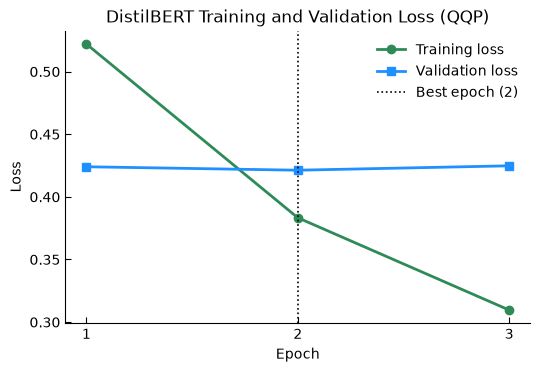

In [8]:
fig, ax = plt.subplots(figsize=(6, 3.8))

ax.plot(curve["epoch"], curve["train_loss"], marker="o", linewidth=2, color=COLORS[0], label="Training loss")
ax.plot(curve["epoch"], curve["val_loss"], marker="s", linewidth=2, color=COLORS[1], label="Validation loss")
ax.axvline(x=best_epoch, color="black", linestyle=":", linewidth=1.2, label=f"Best epoch ({best_epoch})")

ax.set_xticks(curve["epoch"])
ax.set_xlabel("Epoch")
ax.set_ylabel("Loss")
ax.set_title("DistilBERT Training and Validation Loss (QQP)")

style(ax)
ax.legend(loc="best",frameon=False)
fig.savefig(f"{OUT}/fig_training_curve.png", dpi=300, bbox_inches="tight")

plt.show()

In [9]:
datasets = [("QQP val", qqp_val), ("QQP test", qqp_test), ("PAWS test", paws_test)]

for dataset_name, df in datasets:

    probabilities = predict_prob(trainer, df)
    log_results("DistilBERT", dataset_name, df["label"], probabilities)

res = pd.DataFrame(results)

res.to_csv(f"{OUT}/detection_results.csv", index=False)
display(res.round(3))

Map:   0%|          | 0/1000 [00:00<?, ? examples/s]

Map:   0%|          | 0/1000 [00:00<?, ? examples/s]

Map:   0%|          | 0/8000 [00:00<?, ? examples/s]

,model,dataset,accuracy,precision,recall,f1,roc_auc,TN,FP,FN,TP
0,TF-IDF + LogReg,QQP val,0.722,0.625,0.559,0.590,0.799,522,120,158,200
1,TF-IDF + LogReg,QQP test,0.715,0.605,0.530,0.565,0.769,530,121,164,185
2,TF-IDF + LogReg,PAWS test,0.494,0.448,0.618,0.519,0.505,1768,2696,1350,2186
3,DistilBERT,QQP val,0.803,0.669,0.891,0.764,0.889,484,158,39,319
4,DistilBERT,QQP test,0.762,0.619,0.828,0.708,0.854,473,178,60,289
5,DistilBERT,PAWS test,0.492,0.441,0.561,0.494,0.498,1951,2513,1552,1984


## Results

Compare TF-IDF + Logistic Regression with DistilBERT to see which model performs better at identifying paraphrases.

### RQ1: Which model performs better on QQP?

Compare both models using the **QQP test dataset**.

### RQ2: How well do the models perform on PAWS?

Compare each model's performance on **QQP test versus PAWS test**.

### Metrics

- Accuracy
- Precision
- Recall
- F1-score
- Confusion matrix

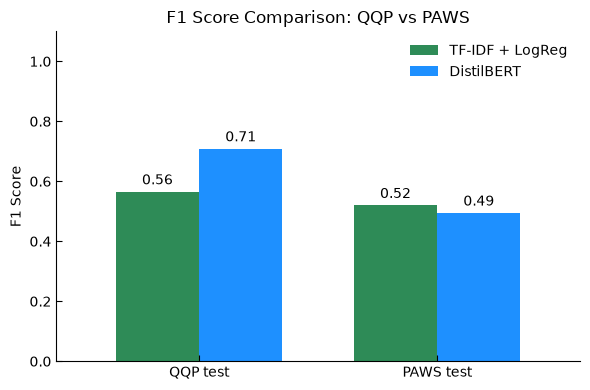

In [10]:
MODELS = ["TF-IDF + LogReg", "DistilBERT"]
DATASETS = ["QQP test", "PAWS test"]


test = res[res["dataset"].isin(DATASETS)].copy()

f1_table = test.pivot(index="dataset", columns="model", values="f1")
f1_table = f1_table.loc[DATASETS, MODELS]

# Bar chart
fig, ax = plt.subplots(figsize=(6, 4))

f1_table.plot(kind="bar", ax=ax, color=COLORS[:2], width=0.7, rot=0)

for bars in ax.containers:
    ax.bar_label(bars, fmt="%.2f", padding=3)


ax.set_xlabel("")
ax.set_ylabel("F1 Score")
ax.set_title("F1 Score Comparison: QQP vs PAWS")
ax.set_ylim(0, 1.1)
ax.set_yticks([0, 0.2, 0.4, 0.6, 0.8, 1.0])
style(ax)

ax.legend(loc="upper right", frameon=False, title="")
plt.tight_layout()
fig.savefig(f"{OUT}/fig_f1_qqp_vs_paws.png", dpi=300, bbox_inches="tight")

plt.show()

### RQ2: change from QQP to PAWS
A large negative change means the model relied on word overlap, which PAWS is designed to expose.

In [11]:
f1 = test.pivot(index="model", columns="dataset", values="f1")
acc = test.pivot(index="model", columns="dataset", values="accuracy")

change = pd.DataFrame({
    "F1 QQP": f1["QQP test"],
    "F1 PAWS": f1["PAWS test"],
    "F1 change": f1["PAWS test"] - f1["QQP test"],
    "Acc QQP": acc["QQP test"],
    "Acc PAWS": acc["PAWS test"],
    "Acc change": acc["PAWS test"] - acc["QQP test"]})

change = change.loc[MODELS]

change.to_csv(f"{OUT}/qqp_to_paws_change.csv")
display(change.round(3))

,F1 QQP,F1 PAWS,F1 change,Acc QQP,Acc PAWS,Acc change
model,,,,,,
TF-IDF + LogReg,0.565,0.519,-0.046,0.715,0.494,-0.221
DistilBERT,0.708,0.494,-0.214,0.762,0.492,-0.270


### ROC curves

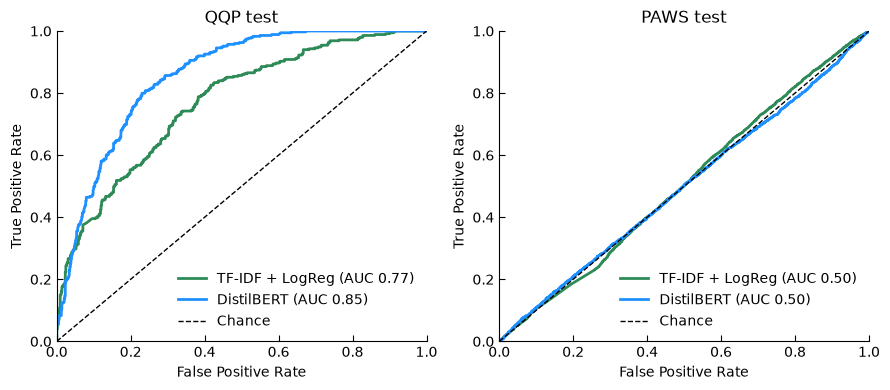

In [12]:
from sklearn.metrics import roc_curve, roc_auc_score

fig, axes = plt.subplots(1, 2, figsize=(9, 4))

datasets = ["QQP test", "PAWS test"]

for ax, dataset in zip(axes, datasets):

    # ROC curve for each model
    for i, model in enumerate(MODELS):

        actual_labels, probabilities = probs[(model, dataset)]

        fpr, tpr, thresholds = roc_curve(actual_labels, probabilities)
        auc = roc_auc_score(actual_labels, probabilities)

        ax.plot(fpr, tpr, color=COLORS[i], linewidth=2, label=f"{model} (AUC {auc:.2f})")

    ax.plot([0, 1], [0, 1], color="black", linestyle="--", linewidth=1, label="Chance")

    ax.set_title(dataset)
    ax.set_xlabel("False Positive Rate")
    ax.set_ylabel("True Positive Rate")

    ax.set_xlim(0, 1)
    ax.set_ylim(0, 1)

    style(ax)

    ax.legend(loc="lower right", frameon=False)

plt.tight_layout()

save_panel(fig, axes[0], "fig_roc_qqp")
save_panel(fig, axes[1], "fig_roc_paws")

plt.show()

## Error Analysis

### 1. What Does the Baseline Model Rely On?

TF-IDF + Logistic Regression model compares sentences based on their word usage.

Two things to examine:

- **Word differences:** Look at which words differ between the two sentences and how strongly these differences influence the model's prediction.
- **Cosine similarity:** Check how much the model relies on overall word similarity when deciding whether two sentences are paraphrases.

In [13]:
words = np.array(tfidf.get_feature_names_out())
coef = lr.coef_[0]
print(f"Coefficient on TF-IDF cosine similarity: {coef[-1]:+.2f}  (positive = more overlap pushes towards paraphrase)\n")

order = np.argsort(coef[:-1])
top = pd.DataFrame({"pushes towards NOT paraphrase": words[order[:12]],
                    "pushes towards paraphrase": words[order[::-1][:12]]})
top.to_csv(f"{OUT}/baseline_top_words.csv", index=False)
top

Coefficient on TF-IDF cosine similarity: +2.21  (positive = more overlap pushes towards paraphrase)



,pushes towards NOT paraphrase,pushes towards paraphrase
0,this,are your
1,in,are people
2,what,possible
3,before,which are
4,singapore,about the
5,do have,of 2016
6,system,is hillary
7,how,your life
8,like,men have
9,canada,good books


### 2. Confident Mistakes

Examine the **five most confident incorrect predictions** made by each model on both the QQP and PAWS test datasets.

These incorrect predictions are examined to identify common mistakes such as:

- **Word order changes:** The model fails to recognise that changing the order of words changes the meaning.
- **Different question focus:** Two questions contain similar words but are asking different things.
- **Misunderstanding meaning:** The model incorrectly identifies sentences as having the same or different meanings.

In [14]:
pd.set_option("display.max_colwidth", 110)

def confident_errors(model, dataset_name, df, n=5):

    true_labels, prob = probs[(model, dataset_name)]

    d = df.reset_index(drop=True).copy()
    d["prob"] = prob                           
    d["pred"] = (prob >= 0.5).astype(int)      

    wrong = d[d.pred != d.label].copy()        
    
    wrong["confidence"] = wrong.prob.where(wrong.pred == 1, 1 - wrong.prob)

    wrong = wrong.sort_values("confidence", ascending=False).head(n)
    wrong["model"], wrong["dataset"] = model, dataset_name
    return wrong

# Top mistakes for each model on each test set
datasets = [("PAWS test", paws_test), ("QQP test", qqp_test)]


error_tables = []

for name, df in datasets:

    for model in MODELS:

        mistakes = confident_errors(model, name, df)
        error_tables.append(mistakes)
        
errors = pd.concat(error_tables, ignore_index=True)

errors = errors[["model", "dataset", "sentence1", "sentence2", "label", "prob"]].round(2)
errors.to_csv(f"{OUT}/confident_errors.csv", index=False)

# Group errors by model and dataset
grouped_errors = errors.groupby(["model", "dataset"], sort=False)

for (model, dataset), group in grouped_errors:

    print(f"{model} on {dataset}")

    columns = ["sentence1", "sentence2", "label", "prob"]
    table = group[columns]
    table = table.reset_index(drop=True)
    display(table)

TF-IDF + LogReg on PAWS test


,sentence1,sentence2,label,prob
0,"Amethi , Musafirkhana and Gauriganj tehsils are now located in the Amethi district .","The Gauriganj , Musafirkhana , and Amethi tehsils are now in Amethi district .",1,0.05
1,"The Amethi , Musafirkhana , and Gauriganj tehsils are now in Amethi district .","Amethi , Musafirkhana and Gauriganj tehsils are now located in the Amethi district .",1,0.05
2,"Arkalochori is a town and a former municipality in the Crete regional unit , Heraklion , Greece .","Arkalochori is a city and a former municipality in the regional unit of Crete , Heraklion , Greece .",1,0.07
3,Calapan is from the provincial capital of Puerto Galera .,"Calapan is from Puerto Galera , the provincial capital .",1,0.07
4,"He was graduated in 1872 from Cumberland University and the Legal Department of Mansfield College , Lebano...","He was graduated from Cumberland University , and from the law department of Mansfield College , Lebanon ,...",1,0.08


DistilBERT on PAWS test


,sentence1,sentence2,label,prob
0,"NDSU ( North Dakota State University ) , which has over 14,500 students , is home to Fargo .","Fargo is home to NDSU ( North Dakota State University ) , which has over 14,500 students .",1,0.05
1,"The most important use of phosphorous acid ( phosphonic acid ) is the production of basic lead phosphite ,...","The most important use of phosphoric acid ( phosphoric acid ) is the production of basic lead phosphite , ...",1,0.06
2,"The most important use of phosphorous acid ( basic lead acid ) is the production of phosphonic phosphite ,...","The most important use of phosphoric acid ( basic lead acid ) is the production of phosphorous phosphite ,...",1,0.06
3,There are two main types of muscular fiber orientations that are responsible for movement : the longitudin...,There are two main types of muscle fibers orientations that are responsible for the movement : the longitu...,1,0.06
4,There are two main types of muscular fiber orientations that are responsible for movement : the longitudin...,There are two main types of muscle fibers orientations that are responsible for the movement : the circula...,1,0.06


TF-IDF + LogReg on QQP test


,sentence1,sentence2,label,prob
0,Why does my dog take her food away from the bowl and eat?,Why do dogs take their food outside of their bowl when they are eating?,1,0.01
1,Is Khan Academy a better online resource than MIT OCW? Why or why not?,Is it better to learn calculus from Khan academy or MIT OCW for a physics student?,1,0.01
2,Is depression curable? Why or why not?,Is dimentia curable?,1,0.02
3,How long does meth say in your urine?,How long does meth stay detectable in the body through testing?,1,0.02
4,Why should a country have two currencies?,Should there be two currencies at once in a country instead of one? Or not?,1,0.02


DistilBERT on QQP test


,sentence1,sentence2,label,prob
0,In what medium does light (photon) travel?,"""If light is a wave, what is the medium that is """"waving""""?""",1,0.02
1,Is Khan Academy a better online resource than MIT OCW? Why or why not?,Is it better to learn calculus from Khan academy or MIT OCW for a physics student?,1,0.02
2,Can hamsters eat apples?,"Can hamsters eat raisins? If so, how harmful are they for them in any way?",1,0.03
3,Is depression curable? Why or why not?,Is dimentia curable?,1,0.03
4,Should black people wear sunblock?,Do black people need to put on sunscreen lotions during summer?,1,0.03


### 3. The Boundary Between Paraphrase and Non-Paraphrase

Examine how confidently each model predicts whether two sentences are paraphrases.

The model gives each sentence pair a **probability between 0 and 1**:

- **Close to 0:** The model believes the sentences have different meanings (not paraphrases).
- **Close to 1:** The model believes the sentences have the same meaning (paraphrases).
- **Close to 0.5:** The model is uncertain about its prediction.


### Ideally:

- **Non-paraphrases grouped near 0:** The model correctly recognises different meanings.
- **Paraphrases grouped near 1:** The model correctly recognises similar meanings.
- **Very little overlap:** The model can clearly distinguish between the two classes.

### Mistakes

- **Overlap around 0.5:** The model struggles to distinguish between paraphrases and non-paraphrases.
- **Non-paraphrases near 1:** The model confidently predicts paraphrases when the sentences actually have different meanings.
- **Paraphrases near 0:** The model confidently predicts non-paraphrases when the sentences actually have the same meaning.

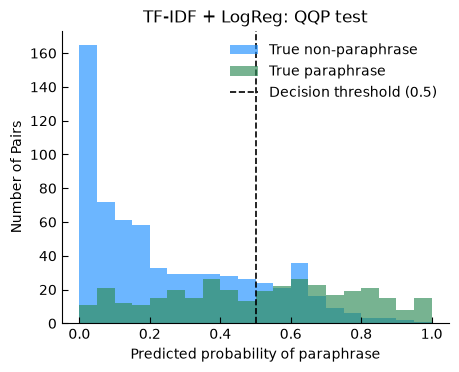

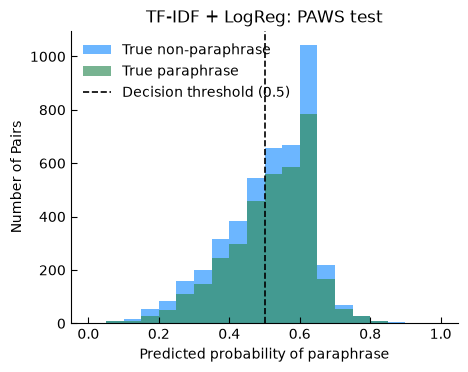

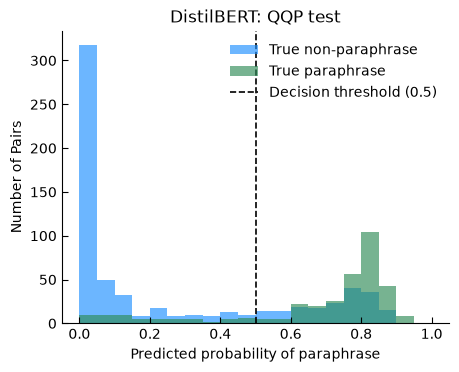

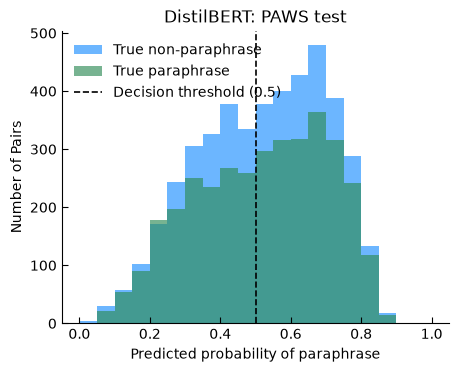

In [15]:
NAMES = {"TF-IDF + LogReg": "tfidf", "DistilBERT": "distilbert", "QQP test": "qqp", "PAWS test": "paws"}

bins = np.linspace(0, 1, 21)

datasets = ["QQP test", "PAWS test"]

for model in MODELS:

    for dataset in datasets:

        actual_labels, probabilities = probs[(model, dataset)]

        non_paraphrase_probs = probabilities[actual_labels == 0]
        paraphrase_probs = probabilities[actual_labels == 1]

        fig, ax = plt.subplots(figsize=(5, 3.8))

        ax.hist(non_paraphrase_probs, bins=bins, color=COLORS[1], alpha=0.65, label="True non-paraphrase")
        ax.hist(paraphrase_probs, bins=bins, color=COLORS[0], alpha=0.65, label="True paraphrase")

        ax.axvline(0.5, color="black", linestyle="--", linewidth=1.2, label="Decision threshold (0.5)")


        ax.set_title(f"{model}: {dataset}")
        ax.set_xlabel("Predicted probability of paraphrase")
        ax.set_ylabel("Number of Pairs")
        style(ax)

        ax.legend(loc="best", frameon=False)

        model_name = NAMES[model]
        dataset_name = NAMES[dataset]
        filename = f"{OUT}/fig_probability_{model_name}_{dataset_name}.png"

        fig.savefig(filename, dpi=300, bbox_inches="tight")
        plt.show()
        plt.close(fig)

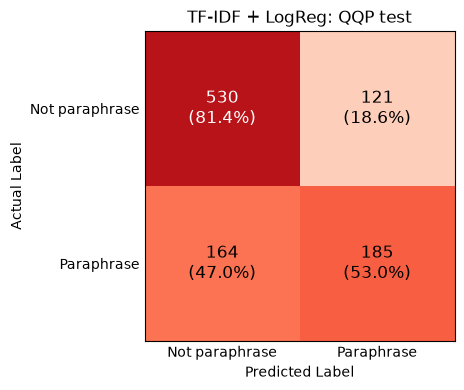

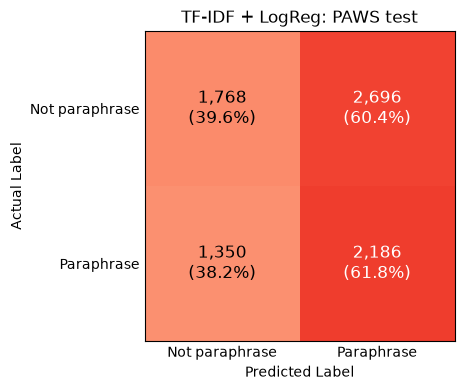

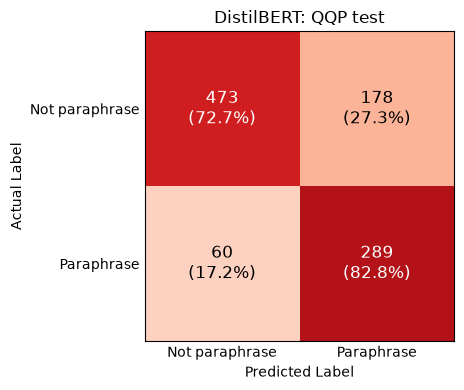

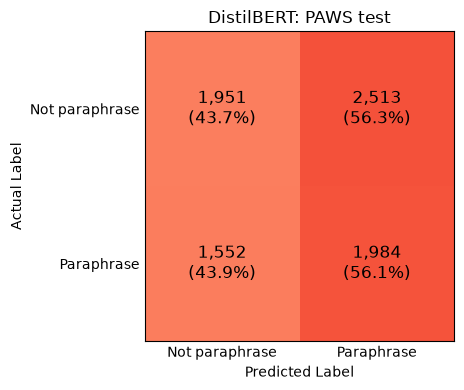

In [16]:
from sklearn.metrics import confusion_matrix

NAMES = {"TF-IDF + LogReg": "tfidf", "DistilBERT": "distilbert", "QQP test": "qqp", "PAWS test": "paws"}

labels = ["Not paraphrase", "Paraphrase"]
datasets = ["QQP test", "PAWS test"]

for model in MODELS:

    for dataset in datasets:

        actual_labels, probabilities = probs[(model, dataset)]
        predictions = (probabilities >= 0.5).astype(int)

        counts = confusion_matrix(actual_labels, predictions, labels=[0, 1])

        row_totals = counts.sum(axis=1, keepdims=True)
        percentages = np.divide(counts, row_totals, out=np.zeros_like(counts, dtype=float), where=row_totals != 0)

        fig, ax = plt.subplots(figsize=(5, 4))

        ax.imshow(percentages, cmap="Reds", vmin=0, vmax=1)

        for row in range(2):
            for col in range(2):

                count = counts[row, col]
                percentage = percentages[row, col]
                text_color = "white" if percentage >= 0.6 else "black"

                ax.text(col, row, f"{count:,}\n({percentage:.1%})", ha="center", va="center", color=text_color, fontsize=12)

        ax.set_xticks([0, 1], labels)
        ax.set_yticks([0, 1], labels)
        ax.set_xlabel("Predicted Label")
        ax.set_ylabel("Actual Label")
        ax.set_title(f"{model}: {dataset}")
        ax.tick_params(axis="both", length=0)
        ax.grid(False)


        model_name = NAMES[model]
        dataset_name = NAMES[dataset]

        filename = f"{OUT}/fig_confusion_{model_name}_{dataset_name}.png"

        fig.tight_layout()
        fig.savefig(filename, dpi=300, bbox_inches="tight")
        plt.show()
        plt.close(fig)

In [18]:
from sklearn.metrics import accuracy_score, f1_score, roc_auc_score

# Check class balance
for name, df in splits.items():
    paraphrase_pct = df.label.mean() * 100
    majority_pct = max(paraphrase_pct, 100 - paraphrase_pct)

    print(f"{name}: {paraphrase_pct:.1f}% paraphrases | {majority_pct:.1f}% majority class")


# Check if test questions appear in training
train_questions = set(qqp_train.sentence1) | set(qqp_train.sentence2)

def overlaps(df):
    return df.sentence1.isin(train_questions) | df.sentence2.isin(train_questions)

for name, df in [("QQP val", qqp_val), ("QQP test", qqp_test)]:
    print(f"{name}: {overlaps(df).mean():.1%} overlap with training")


results = []

no_overlap = ~overlaps(qqp_test).to_numpy()

for model in ["TF-IDF + LogReg", "DistilBERT"]:

    y, prob = probs[(model, "QQP test")]

    groups = {"All pairs": np.ones(len(y), dtype=bool), "No overlap": no_overlap}

    for group, items in groups.items():
        predictions = (prob[items] >= 0.5).astype(int)

        results.append({
            "Model": model,
            "Group": group,
            "Pairs": items.sum(),
            "Accuracy": accuracy_score(y[items], predictions),
            "F1": f1_score(y[items], predictions),
            "ROC-AUC": roc_auc_score(y[items], prob[items])})

display(pd.DataFrame(results).round(3))

qqp_train: 36.8% paraphrases | 63.2% majority class
qqp_val: 35.8% paraphrases | 64.2% majority class
qqp_test: 34.9% paraphrases | 65.1% majority class
paws_test: 44.2% paraphrases | 55.8% majority class
QQP val: 9.0% overlap with training
QQP test: 6.7% overlap with training


,Model,Group,Pairs,Accuracy,F1,ROC-AUC
0,TF-IDF + LogReg,All pairs,1000,0.715,0.565,0.769
1,TF-IDF + LogReg,No overlap,933,0.711,0.505,0.746
2,DistilBERT,All pairs,1000,0.762,0.708,0.854
3,DistilBERT,No overlap,933,0.758,0.682,0.851
